# Praktikum Kecerdasan Buatan: Text Classification

Nama: Tika Altiora Sitanggang | NIM: 42324025 | Prodi: D3TI

## Tujuan Praktikum

Tujuan praktikum ini adalah melakukan semua tahap klasifikasi teks, mulai dari membaca data, membersihkan teks, mengubah teks menjadi angka, melatih model, sampai mengevaluasi hasilnya. Kasus yang dipakai adalah mendeteksi pesan SMS spam atau bukan spam (ham).

Tahapan yang dikerjakan di notebook ini:

* 1. Membaca dataset
* 2. Preprocessing teks dengan NLTK
* 3. Mengubah label menjadi angka dan mengecek jumlah tiap kelas
* 4. Membagi data menjadi data latih dan data uji
* 5. Ekstraksi fitur dengan TF-IDF
* 6. Melatih model Naive Bayes
* 7. Evaluasi model (akurasi, classification report, confusion matrix)
* 8. Mencoba model dengan teks baru
* 9. Kesimpulan

Catatan: file Text_classification.csv diletakkan satu folder dengan notebook ini, jadi path yang dipakai adalah path relatif. Di modul asli path-nya /content/Text_classification.csv karena dijalankan di Google Colab.

## 1. Membaca Dataset

Klasifikasi teks adalah proses mengelompokkan teks ke dalam kategori tertentu. Di sini kategorinya hanya dua, yaitu ham (pesan biasa) dan spam (pesan sampah atau iklan).

Pada sel di bawah, pandas dipakai untuk membaca file CSV ke dalam DataFrame bernama df. Fungsi head() menampilkan 5 baris pertama supaya kita tahu isi datanya. Dataset punya dua kolom:

* Category: label pesan (ham atau spam)
* Message: isi pesan SMS

In [1]:
import pandas as pd

df = pd.read_csv('Text_classification.csv')
print(df.head())

  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


Sebelum lanjut, dicek dulu ukuran data dan apakah ada data kosong. Ini penting karena data kosong bisa membuat proses preprocessing error. Hasilnya, dataset berisi 5572 pesan dan tidak ada nilai yang kosong, jadi data aman dipakai langsung.

In [2]:
print("Ukuran data (baris, kolom):", df.shape)
print("\nJumlah data kosong per kolom:")
print(df.isnull().sum())

Ukuran data (baris, kolom): (5572, 2)

Jumlah data kosong per kolom:
Category    0
Message     0
dtype: int64


## 2. Preprocessing Teks dengan NLTK

NLTK (Natural Language Toolkit) adalah pustaka Python untuk membantu komputer menganalisis, memproses, dan memahami teks. NLTK punya alat untuk tokenisasi, stemming, lemmatization, penghapusan stopword, dan analisis teks lainnya.

Teks mentah seperti SMS biasanya berantakan (huruf besar kecil campur, ada angka, tanda baca, dan kata yang tidak penting). Karena itu teks perlu dibersihkan dulu supaya model fokus ke kata yang benar benar membawa makna.

Pada sel berikutnya ada dua bagian. Bagian pertama mengunduh resource NLTK yang dibutuhkan:

* punkt dan punkt_tab: untuk tokenisasi (memecah kalimat menjadi kata)
* stopwords: daftar kata umum bahasa Inggris yang tidak terlalu bermakna (misalnya the, is, you)
* wordnet: kamus yang dipakai lemmatizer

Bagian kedua adalah fungsi clean_text() yang melakukan langkah berikut secara berurutan:

* 1. Lowercase: semua huruf diubah ke huruf kecil supaya Free dan free dianggap kata yang sama
* 2. Hapus angka: karakter angka dibuang memakai regex
* 3. Hapus tanda baca: semua tanda baca dibuang
* 4. Tokenisasi: kalimat dipecah menjadi daftar kata
* 5. Hapus stopwords: kata umum yang tidak penting dibuang
* 6. Lemmatization: kata diubah ke bentuk dasarnya (misalnya lives menjadi life)
* 7. Hasil akhir digabung lagi menjadi satu kalimat dengan spasi

Satu penyesuaian kecil dari modul: daftar stopwords disimpan dulu ke variabel stop_words (dalam bentuk set) di luar fungsi. Hasilnya sama persis, tetapi prosesnya jauh lebih cepat karena daftar tidak dibaca ulang untuk setiap kata.

Setelah fungsi dibuat, fungsi diterapkan ke seluruh kolom Message dengan apply(), dan hasilnya disimpan di kolom baru bernama clean_text. Pesan asli tetap disimpan di kolom Message sehingga bisa dibandingkan sebelum dan sesudah dibersihkan.

In [3]:
# Download resource NLTK yang diperlukan
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

# Import library untuk preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()

# Simpan daftar stopwords sekali saja supaya proses lebih cepat
stop_words = set(stopwords.words('english'))

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower()  # Ubah menjadi lowercase
    text = re.sub(r'\d+', '', text)  # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation))  # Hapus tanda baca
    words = word_tokenize(text)  # Tokenisasi
    words = [word for word in words if word not in stop_words]  # Hapus stopwords
    words = [lemmatizer.lemmatize(word) for word in words]  # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['Message'].apply(clean_text)

# Cek hasil preprocessing
print("\nHasil Preprocessing:\n", df[['Message', 'clean_text']].head())

[nltk_data] Error loading punkt_tab: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading punkt: <urlopen error pathsec.urlopen: no
[nltk_data]     validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading stopwords: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading wordnet: <urlopen error pathsec.urlopen: no
[nltk_data]     validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>


LookupError: 
**********************************************************************
  Resource 'stopwords' not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('stopwords')

  For more information see: https://www.nltk.org/data.html

  Attempted to load 'corpora/stopwords'

  Searched in:
    - 'C:\\Users\\tikas/nltk_data'
    - 'c:\\Users\\tikas\\anaconda3\\nltk_data'
    - 'c:\\Users\\tikas\\anaconda3\\share\\nltk_data'
    - 'c:\\Users\\tikas\\anaconda3\\lib\\nltk_data'
    - 'C:\\Users\\tikas\\AppData\\Roaming\\nltk_data'
    - 'C:\\nltk_data'
    - 'D:\\nltk_data'
    - 'E:\\nltk_data'
**********************************************************************


Pada hasil di atas terlihat perbedaan antara kolom Message dan clean_text. Contohnya pesan baris ke 4, "Nah I don't think he goes to usf, he lives around though", berubah menjadi "nah dont think go usf life around though". Huruf sudah kecil semua, tanda baca hilang, kata umum seperti he dan to dibuang, dan kata goes serta lives sudah menjadi bentuk dasarnya, yaitu go dan life. Teks seperti ini yang akan dipakai untuk proses selanjutnya.

## 3. Mengubah Label dan Mengecek Jumlah Kelas

Model machine learning hanya bisa memproses angka, jadi label ham dan spam diubah menjadi angka dengan fungsi map():

* ham menjadi 0
* spam menjadi 1

Setelah itu value_counts() dipakai untuk menghitung jumlah data di tiap kelas. Hasilnya ada 4825 pesan ham dan 747 pesan spam. Artinya datanya tidak seimbang (imbalanced), karena pesan ham jauh lebih banyak daripada spam. Hal ini perlu diingat saat membaca hasil evaluasi nanti, karena akurasi saja bisa terlihat bagus padahal model kurang baik mengenali kelas yang jumlahnya sedikit.

In [ ]:
# Ubah label dari 'ham'/'spam' menjadi 0/1
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})

# Cek jumlah masing-masing kelas
print(df['Category'].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


## 4. Membagi Data Latih dan Data Uji

Data dibagi menjadi dua bagian. Data latih dipakai untuk melatih model, sedangkan data uji dipakai untuk mengetes seberapa baik model pada data yang belum pernah dilihat.

Penjelasan kodenya:

* X adalah fitur (teks yang sudah bersih, kolom clean_text)
* y adalah label (kolom Category)
* test_size=0.2 artinya 20% data dipakai untuk pengujian dan 80% untuk pelatihan
* random_state=42 membuat pembagian data selalu sama setiap kali dijalankan, jadi hasilnya bisa diulang
* stratify=y menjaga perbandingan ham dan spam di data latih dan data uji tetap sama dengan data aslinya. Ini penting karena datanya tidak seimbang

In [ ]:
from sklearn.model_selection import train_test_split

# Pisahkan fitur dan label
X = df['clean_text']
y = df['Category']

# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Untuk memastikan pembagian datanya benar, jumlah data dan proporsi kelas pada data latih dan data uji dicek di sel berikut. Data latih berisi 4457 pesan dan data uji berisi 1115 pesan. Proporsi spam di keduanya sama, sekitar 13%, sehingga stratify bekerja sesuai tujuannya.

In [ ]:
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji  :", len(X_test))
print("\nProporsi kelas di data latih:")
print(y_train.value_counts(normalize=True).round(3))
print("\nProporsi kelas di data uji:")
print(y_test.value_counts(normalize=True).round(3))

Jumlah data latih: 4457
Jumlah data uji  : 1115

Proporsi kelas di data latih:
Category
0    0.866
1    0.134
Name: proportion, dtype: float64

Proporsi kelas di data uji:
Category
0    0.866
1    0.134
Name: proportion, dtype: float64


## 5. Ekstraksi Fitur dengan TF-IDF

Teks tidak bisa langsung dimasukkan ke model, jadi perlu diubah menjadi angka. Caranya memakai TF-IDF (Term Frequency, Inverse Document Frequency). Metode ini memberi bobot pada setiap kata:

* TF: seberapa sering sebuah kata muncul di satu pesan
* IDF: seberapa jarang kata itu muncul di seluruh pesan. Kata yang jarang muncul di banyak pesan diberi bobot lebih besar karena lebih bisa membedakan satu pesan dari pesan lain

Pengaturan yang dipakai pada TfidfVectorizer:

* ngram_range=(1,2): memakai unigram (satu kata) dan bigram (dua kata berurutan, misalnya free entry), jadi sedikit konteks kata ikut terbawa
* max_features=5000: hanya 5000 fitur terpenting yang dipakai supaya model tidak terlalu berat

Ada satu hal penting pada kode ini. Pada data latih dipakai fit_transform(), yaitu vectorizer mempelajari kosakata dan bobot dari data latih lalu mengubahnya. Pada data uji hanya dipakai transform(), yaitu memakai kosakata yang sudah dipelajari dari data latih. Cara ini dilakukan supaya data uji benar benar tidak ikut "dilihat" saat pelatihan.

Hasil shape (4457, 5000) berarti ada 4457 pesan latih, dan masing masing diwakili oleh 5000 fitur angka.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), max_features=5000)  # Menggunakan bigram
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("\nTF-IDF Shape (Train):", X_train_tfidf.shape)


TF-IDF Shape (Train): (4457, 5000)


## 6. Melatih Model Naive Bayes

Model yang dipakai adalah Multinomial Naive Bayes. Model ini bekerja dengan menghitung peluang sebuah pesan termasuk spam atau ham berdasarkan kata kata yang ada di dalamnya. Jenis Multinomial cocok dipakai untuk data teks yang berupa hitungan atau bobot kata, seperti hasil TF-IDF.

Parameter alpha=0.1 adalah nilai smoothing. Fungsinya mencegah peluang bernilai nol ketika ada kata yang tidak pernah muncul di salah satu kelas pada data latih.

Langkah di sel berikut:

* fit(): melatih model memakai data latih (fitur TF-IDF dan labelnya)
* predict(): memprediksi kelas dari data uji, hasilnya disimpan di y_pred

In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model Naive Bayes
model = MultinomialNB(alpha=0.1)

# Train model
model.fit(X_train_tfidf, y_train)

# Prediksi hasil
y_pred = model.predict(X_test_tfidf)

## 7. Evaluasi Model

Evaluasi dilakukan dengan membandingkan hasil prediksi (y_pred) dengan label sebenarnya (y_test). Ada dua ukuran yang ditampilkan.

Akurasi adalah persentase prediksi yang benar dari seluruh data uji.

Classification report menampilkan ukuran yang lebih rinci untuk tiap kelas:

* precision: dari semua pesan yang diprediksi sebagai suatu kelas, berapa persen yang benar
* recall: dari semua pesan yang sebenarnya termasuk suatu kelas, berapa persen yang berhasil ditemukan model
* f1-score: rata rata gabungan precision dan recall
* support: jumlah data sebenarnya di kelas tersebut

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.979372197309417

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



Cara membaca hasilnya:

* Akurasi sebesar 0.9794 atau sekitar 97,9%, artinya hampir semua pesan di data uji diprediksi dengan benar.
* Untuk kelas 0 (ham), precision 0.98 dan recall 1.00. Hampir semua pesan ham berhasil dikenali.
* Untuk kelas 1 (spam), precision 0.98 berarti hampir semua pesan yang ditandai spam memang benar spam. Namun recall hanya 0.86, artinya masih ada sekitar 14% pesan spam yang lolos dan dianggap ham.
* Karena datanya tidak seimbang, nilai akurasi yang tinggi sebagian besar dibantu oleh banyaknya pesan ham. Itulah kenapa precision, recall, dan f1-score per kelas perlu dilihat juga. Pada baris macro avg (rata rata biasa antar kelas), recall turun menjadi 0.93 dan f1-score menjadi 0.95, lebih rendah dari akurasi karena recall kelas spam lebih rendah.

## 8. Confusion Matrix

Confusion matrix adalah tabel evaluasi yang menunjukkan bagaimana model klasifikasi bekerja dalam memprediksi kelas data. Isinya ada empat bagian:

* True Positive (TP): model benar memprediksi spam sebagai spam
* True Negative (TN): model benar memprediksi ham sebagai ham
* False Positive (FP): model salah memprediksi ham sebagai spam
* False Negative (FN): model salah memprediksi spam sebagai ham

Pada kode di bawah, confusion_matrix() menghitung tabelnya, lalu ravel() mengubahnya menjadi empat angka (TN, FP, FN, TP). Angka angka itu dimasukkan ke DataFrame dan diberi keterangan, kemudian digambar sebagai heatmap memakai seaborn. Warna yang lebih gelap menunjukkan jumlah yang lebih besar.

In [ ]:
# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Definisi elemen dalam confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()

# Buat dataframe confusion matrix
df_conf_matrix = pd.DataFrame(conf_matrix, index=['Actual Ham', 'Actual Spam'], columns=['Predicted Ham', 'Predicted Spam'])

# Label untuk TP, FP, FN, TN
labels = np.array([["TN = {}\n(True Negative)".format(TN), "FP = {}\n(False Positive)".format(FP)],
                   ["FN = {}\n(False Negative)".format(FN), "TP = {}\n(True Positive)".format(TP)]])

Sel berikut menggambar heatmap dari confusion matrix. Parameter annot=labels dipakai agar tiap kotak menampilkan keterangan TN, FP, FN, dan TP beserta jumlahnya, cmap='Blues' mengatur warna biru, dan plt.show() menampilkan gambarnya.

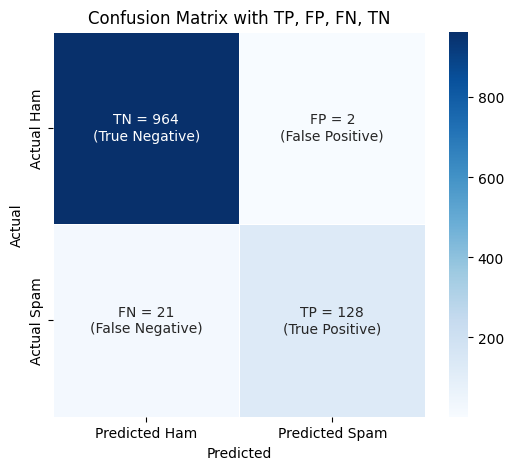

In [ ]:
# Plot heatmap dengan keterangan
plt.figure(figsize=(6,5))
ax = sns.heatmap(df_conf_matrix, annot=labels, fmt='', cmap='Blues', linewidths=0.5, cbar=True)

# Tambahkan label
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with TP, FP, FN, TN')
plt.show()

Cara membaca confusion matrix di atas dari 1115 data uji:

* TN = 964: ada 964 pesan ham yang benar diprediksi ham
* FP = 2: hanya 2 pesan ham yang salah diprediksi spam
* FN = 21: ada 21 pesan spam yang salah diprediksi ham
* TP = 128: ada 128 pesan spam yang benar diprediksi spam

Jumlah prediksi yang benar adalah 964 + 128 = 1092 dari 1115 data, dan nilai ini cocok dengan akurasi 0.9794. Model sangat jarang salah menandai pesan biasa sebagai spam (hanya 2), tetapi masih ada 21 pesan spam yang lolos. Dalam kasus filter spam, kesalahan FP biasanya dianggap lebih merugikan karena pesan penting bisa ikut terblokir, jadi hasil ini cukup baik.

## 9. Mencoba Model dengan Teks Baru

Tahap terakhir adalah menguji model dengan dua kalimat baru yang tidak ada di dataset. Teks baru harus diperlakukan sama seperti data latih, yaitu:

* 1. Dibersihkan dengan fungsi clean_text() yang sama
* 2. Diubah menjadi angka dengan vectorizer yang sudah dilatih. Di sini hanya transform() yang dipakai, bukan fit_transform()
* 3. Diprediksi dengan model.predict()

Hasil prediksi berupa 0 atau 1, lalu diubah kembali menjadi tulisan Ham atau Spam supaya mudah dibaca.

In [ ]:
# Contoh teks baru
new_texts = ["Congratulations! You won a free trip to Bali.",
             "Hey, are you coming to the party tonight?"]

# Preprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]

# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer.transform(new_texts_clean)

# Prediksi
predictions = model.predict(new_texts_tfidf)

# Output hasil prediksi
for text, label in zip(new_texts, predictions):
    print(f"\nMessage: {text} \nPredicted: {'Spam' if label == 1 else 'Ham'}")


Message: Congratulations! You won a free trip to Bali. 
Predicted: Spam

Message: Hey, are you coming to the party tonight? 
Predicted: Ham


Hasilnya sesuai harapan. Kalimat "Congratulations! You won a free trip to Bali." diprediksi Spam, karena memuat kata kata yang khas dari pesan penipuan atau hadiah seperti congratulations, won, dan free. Kalimat "Hey, are you coming to the party tonight?" diprediksi Ham karena merupakan percakapan biasa.

## Kesimpulan

* Klasifikasi teks dilakukan dengan tahapan: preprocessing (lowercase, hapus angka dan tanda baca, tokenisasi, hapus stopwords, lemmatization), pelabelan angka, pembagian data, ekstraksi fitur TF-IDF, pelatihan model, lalu evaluasi.
* Model Multinomial Naive Bayes dengan TF-IDF (unigram dan bigram) menghasilkan akurasi 97,9% pada data uji untuk mendeteksi pesan spam.
* Dari 149 pesan spam di data uji, 128 berhasil terdeteksi (recall 0.86), sedangkan dari 966 pesan ham hanya 2 yang salah ditandai spam.
* Karena datanya tidak seimbang, evaluasi tidak cukup hanya melihat akurasi. Precision, recall, dan confusion matrix ikut dilihat supaya gambaran performa model lebih jujur.
* Model juga berhasil memprediksi dua contoh teks baru dengan benar.